
# Blinkit Grocery Sales Analysis

## Objective
Analyze Blinkit sales data to identify:
- Top-performing product categories
- Best-performing outlets and outlet types
- Impact of pricing, visibility and outlet age on sales
- Product preferences based on fat content

## Tools Used
Python, Pandas, NumPy, Matplotlib


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("Tableau BlinkIT Grocery Project U16955293080 (4) - Tableau BlinkIT Grocery Project.csv")
df.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


In [3]:
len(df)

8523

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   str    
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   str    
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   str    
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   str    
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   str    
 9   Outlet_Location_Type       8523 non-null   str    
 10  Outlet_Type                8523 non-null   str    
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 799.2 KB


In [5]:
df.describe()

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,7060.000000,8523.000000,8523.000000,8523.000000,8523.000000
mean,12.857645,0.066132,140.992782,1997.831867,2181.288914
std,4.643456,0.051598,62.275067,8.371760,1706.499616
min,4.555000,0.000000,31.290000,1985.000000,33.290000
25%,8.773750,0.026989,93.826500,1987.000000,834.247400
50%,12.600000,0.053931,143.012800,1999.000000,1794.331000
75%,16.850000,0.094585,185.643700,2004.000000,3101.296400
max,21.350000,0.328391,266.888400,2009.000000,13086.964800


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df[df.duplicated()]
#there are no duplicate values

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales


In [8]:
df.isnull().sum()
#item weight has 1463 missing values 
#outlet size has 2410 missing values

Item_Identifier                 0
Item_Weight                  1463
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  2410
Outlet_Location_Type            0
Outlet_Type                     0
Item_Outlet_Sales               0
dtype: int64

In [9]:
df["Item_Weight"] = df["Item_Weight"].fillna(df["Item_Weight"].mean())

In [10]:
df.head(10)

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.300000,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.920000,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.500000,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.200000,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.930000,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052
5,FDP36,10.395000,Regular,0.000000,Baking Goods,51.4008,OUT018,2009,Medium,Tier 3,Supermarket Type2,556.6088
6,FDO10,13.650000,Regular,0.012741,Snack Foods,57.6588,OUT013,1987,High,Tier 3,Supermarket Type1,343.5528
7,FDP10,12.857645,Low Fat,0.127470,Snack Foods,107.7622,OUT027,1985,Medium,Tier 3,Supermarket Type3,4022.7636
8,FDH17,16.200000,Regular,0.016687,Frozen Foods,96.9726,OUT045,2002,NaN,Tier 2,Supermarket Type1,1076.5986
9,FDU28,19.200000,Regular,0.094450,Frozen Foods,187.8214,OUT017,2007,NaN,Tier 2,Supermarket Type1,4710.5350


In [11]:
df["Outlet_Size"] = df["Outlet_Size"].fillna(df["Outlet_Size"].mode()[0])

In [12]:
#normalising the dataset
df["Item_Fat_Content"] = df["Item_Fat_Content"].replace({"Low Fat" : "low fat" , "LF" : "low fat", "reg" : "Regular"})

In [13]:
#df["Outlet_Age"] = 2026 - df["Outlet_Establishment_Year"]
#using datetime library make it dynamic. Every year, the age will change automatically
from datetime import datetime
year = datetime.now().year
df["Outlet_Age"] = year - df["Outlet_Establishment_Year"]


In [14]:
print(df["Item_Weight"].isnull().sum())
print(df["Outlet_Size"].isnull().sum())

0
0


In [15]:
#KPI Summary
total_sales = df["Item_Outlet_Sales"].sum()
avg_sales = df["Item_Outlet_Sales"].mean()
total_products = df["Item_Identifier"].nunique()
total_outlets = df["Outlet_Identifier"].nunique()

print("Total Sales:", round(total_sales,2))
print("Average Sales:", round(avg_sales,2))
print("Unique Products:", total_products)
print("Unique Outlets:", total_outlets)

Total Sales: 18591125.41
Average Sales: 2181.29
Unique Products: 1559
Unique Outlets: 10


In [16]:
#1. which item generates the total highest sales
df.groupby("Item_Type")["Item_Outlet_Sales"].sum().idxmax()
#conclusion - fruits and vegetables are the highes selling item. which could mean that the people are health conscious.

'Fruits and Vegetables'

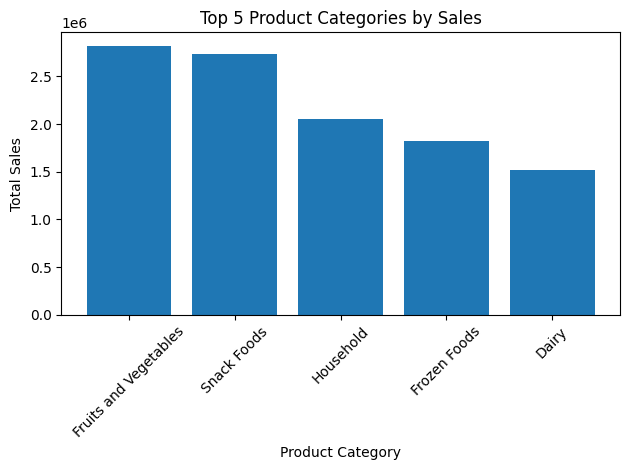

In [17]:
#graph for the top 5 best selling items
top5itemsbysales = df.groupby("Item_Type")["Item_Outlet_Sales"].sum().sort_values(ascending = False).head(5)
plt.bar(top5itemsbysales.index,top5itemsbysales.values)
plt.title("Top 5 Product Categories by Sales")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Top 5 Categories Contribution to Total Sales')

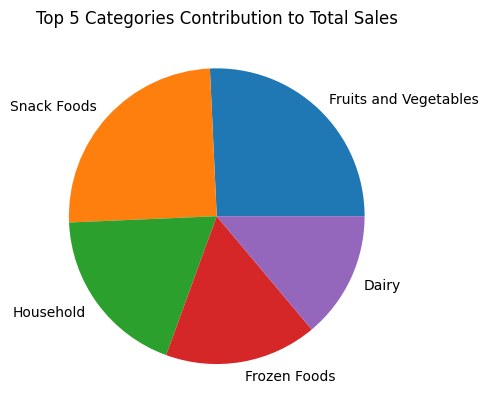

In [18]:
i_sales = df.groupby("Item_Type")["Item_Outlet_Sales"].sum()
i_sales_per = (i_sales/i_sales.sum())*100
per_sales = i_sales_per.sort_values(ascending = False).nlargest(5)    #top 5 highest selling products by percentage 
plt.pie(per_sales,labels = per_sales.index)
#conclusion - fruits and vegetabkes are the highest contributor to the sales. the seller should stock more of such products 
#snack foods is the 2nd largest contributer to the sales. teh top 5 itmes suggest thta people order mor of everyday items which lead to the increase in the sales  
plt.title("Top 5 Categories Contribution to Total Sales")

In [19]:
df.groupby("Item_Fat_Content")["Item_Outlet_Sales"].sum().sort_values(ascending = False)
#conclusion - products with low fats sell more which mean the people are more aware about their health

Item_Fat_Content
low fat    1.190409e+07
Regular    6.687031e+06
Name: Item_Outlet_Sales, dtype: float64

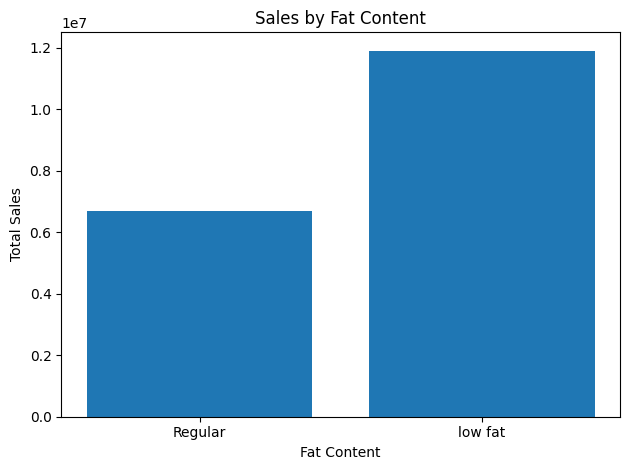

In [20]:
#comparision between the sales of goods according to their fat level
plt.bar(df.groupby("Item_Fat_Content")["Item_Outlet_Sales"].sum().index,
        df.groupby("Item_Fat_Content")["Item_Outlet_Sales"].sum().values)
plt.title("Sales by Fat Content")
plt.xlabel("Fat Content")
plt.ylabel("Total Sales")
plt.tight_layout()

In [21]:
#which store type perfroms the best for low fat products
c= df[df["Item_Fat_Content"]=="low fat"].groupby("Outlet_Type")["Item_Outlet_Sales"].sum().sort_values(ascending = False)
#this displays the sum of the low fat content product sales for each outlet type
print("Outlet best for low fat products = ", c.idxmax())
#conclusion - supermarket type1 is the best seller for low fat products. this means that people there have a stronger preference towards low fat products 

Outlet best for low fat products =  Supermarket Type1


In [22]:
#which outlet generates the highest total 
df.groupby("Outlet_Location_Type")["Item_Outlet_Sales"].sum().sort_values(ascending = False)

Outlet_Location_Type
Tier 3    7.636753e+06
Tier 2    6.472314e+06
Tier 1    4.482059e+06
Name: Item_Outlet_Sales, dtype: float64

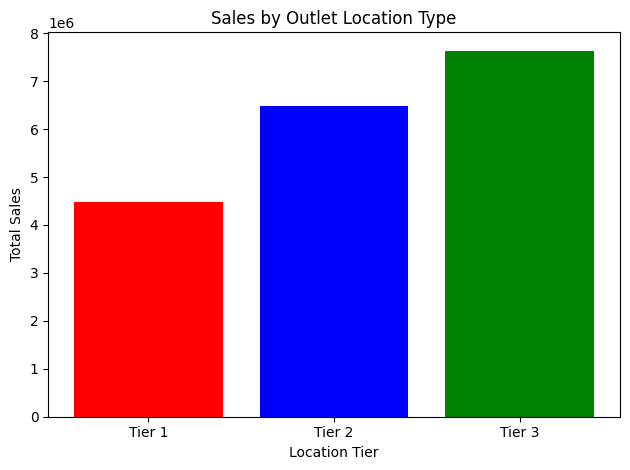

In [23]:
plt.bar(df.groupby("Outlet_Location_Type")["Item_Outlet_Sales"].sum().index,
        df.groupby("Outlet_Location_Type")["Item_Outlet_Sales"].sum().values, color = ("red","blue","green") )
plt.title("Sales by Outlet Location Type")
plt.xlabel("Location Tier")
plt.ylabel("Total Sales")
plt.tight_layout()

In [24]:
#which outlet type generates the highest total
df.groupby("Outlet_Type")["Item_Outlet_Sales"].sum().sort_values(ascending = False)
#conclusion = bigger supermarket sgenerates higher sales 

Outlet_Type
Supermarket Type1    1.291734e+07
Supermarket Type3    3.453926e+06
Supermarket Type2    1.851823e+06
Grocery Store        3.680343e+05
Name: Item_Outlet_Sales, dtype: float64

In [25]:
df.groupby("Outlet_Identifier")["Item_Outlet_Sales"].sum()

Outlet_Identifier
OUT010    1.883402e+05
OUT013    2.142664e+06
OUT017    2.167465e+06
OUT018    1.851823e+06
OUT019    1.796941e+05
OUT027    3.453926e+06
OUT035    2.268123e+06
OUT045    2.036725e+06
OUT046    2.118395e+06
OUT049    2.183970e+06
Name: Item_Outlet_Sales, dtype: float64

In [26]:
outlet_item_sales = (
    df.groupby(["Outlet_Identifier", "Item_Type"])["Item_Outlet_Sales"]
    .sum()
    .reset_index()
)

best_category_per_outlet = (
    outlet_item_sales.loc[
        outlet_item_sales.groupby("Outlet_Identifier")["Item_Outlet_Sales"].idxmax()
    ]
)

print(best_category_per_outlet)
#conclusion - the top selling item differs accross different categories. this means that the customer demands variers across different outlets.
# fruits and vegetables and snack foods are the best selling items across all outlets

    Outlet_Identifier              Item_Type  Item_Outlet_Sales
13             OUT010            Snack Foods         25942.8970
22             OUT013  Fruits and Vegetables        341526.7706
38             OUT017  Fruits and Vegetables        319504.1040
61             OUT018            Snack Foods        278714.5328
77             OUT019            Snack Foods         25653.2740
86             OUT027  Fruits and Vegetables        576028.1886
109            OUT035            Snack Foods        355573.8190
118            OUT045  Fruits and Vegetables        326414.4422
134            OUT046  Fruits and Vegetables        304751.3076
157            OUT049            Snack Foods        350244.0900


In [27]:
#which product category sells the most in each outlet location type
outlet_item_sales = (
    df.groupby(["Outlet_Location_Type", "Item_Type"])["Item_Outlet_Sales"]
    .sum()
    .reset_index()
)
outlet_item_sales
outlet_item_sales.loc[outlet_item_sales.groupby("Outlet_Location_Type")["Item_Outlet_Sales"].idxmax()]

,Outlet_Location_Type,Item_Type,Item_Outlet_Sales
6,Tier 1,Fruits and Vegetables,6.639191e+05
29,Tier 2,Snack Foods,9.550834e+05
38,Tier 3,Fruits and Vegetables,1.205575e+06


In [28]:
#which combination of outlet type and product category generates the highest revenue
s1 = df.groupby(["Outlet_Type","Item_Type"])["Item_Outlet_Sales"].sum().reset_index()
#s1.loc[s1.groupby("Outlet_Type")["Item_Outlet_Sales"].idxmax()] - this gives us the product category which works the best for EACH outlet type.
#buy here we want the best out of these. so we use,
s1.loc[s1["Item_Outlet_Sales"].idxmax()]
#conclusion - Customers purchase Fruits and Vegetables more frequently than other product categories in Supermarket Type1 outlets.

Outlet_Type              Supermarket Type1
Item_Type            Fruits and Vegetables
Item_Outlet_Sales             1931957.8522
Name: 22, dtype: object

In [29]:
#average mrp of each product
df.groupby("Item_Type")["Item_MRP"].mean()

Item_Type
Baking Goods             126.380766
Breads                   140.952669
Breakfast                141.788151
Canned                   139.763832
Dairy                    148.499208
Frozen Foods             138.503366
Fruits and Vegetables    144.581235
Hard Drinks              137.077928
Health and Hygiene       130.818921
Household                149.424753
Meat                     139.882032
Others                   132.851430
Seafood                  141.841719
Snack Foods              146.194934
Soft Drinks              131.492506
Starchy Foods            147.838023
Name: Item_MRP, dtype: float64

In [30]:
#products with the highest MRP 
df.groupby("Item_Type")["Item_MRP"].mean().sort_values(ascending = False)

Item_Type
Household                149.424753
Dairy                    148.499208
Starchy Foods            147.838023
Snack Foods              146.194934
Fruits and Vegetables    144.581235
Seafood                  141.841719
Breakfast                141.788151
Breads                   140.952669
Meat                     139.882032
Canned                   139.763832
Frozen Foods             138.503366
Hard Drinks              137.077928
Others                   132.851430
Soft Drinks              131.492506
Health and Hygiene       130.818921
Baking Goods             126.380766
Name: Item_MRP, dtype: float64

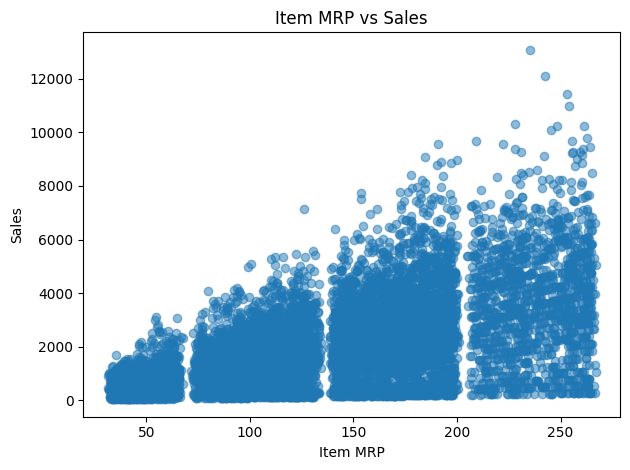

In [31]:
plt.scatter(df["Item_MRP"],df["Item_Outlet_Sales"],alpha = 0.5)
plt.title("Item MRP vs Sales")
plt.xlabel("Item MRP")
plt.ylabel("Sales")
plt.tight_layout()

In [32]:
df["Item_MRP"].corr(df["Item_Outlet_Sales"])
#conclusion - the correlation between the two suggests that there is a moderate postive relationship
#we can say that as the MRP increases, the sales also increases, whcih mean that costly products contribute more to the sale.
#but the relationship is not that strong. which means that MRP is not the sole contributer to the sales. 
#there are other factors that affect the sales as well

np.float64(0.5675744466569193)

In [33]:
#df[["Item_Visibility","Item_Outlet_Sales"]].dtypes
#for series is not callable error, remove the paranthesis
#since both the columns are numerical, we can find the correlation
df["Item_Visibility"].corr(df["Item_Outlet_Sales"])
#conclusion - the relationship is very weak to derive any possible outcome. it does not draw any meaningful results.

np.float64(-0.12862461222077026)

In [34]:
df.groupby("Outlet_Age")["Item_Outlet_Sales"].sum().sort_values(ascending = False)

Outlet_Age
41    3.633620e+06
22    2.268123e+06
27    2.183970e+06
19    2.167465e+06
39    2.142664e+06
29    2.118395e+06
24    2.036725e+06
17    1.851823e+06
28    1.883402e+05
Name: Item_Outlet_Sales, dtype: float64

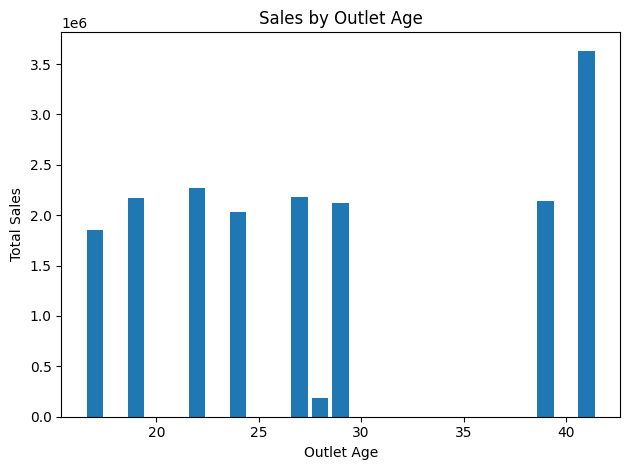

In [35]:
plt.bar(df.groupby("Outlet_Age")["Item_Outlet_Sales"].sum().sort_values(ascending = False).index,
        df.groupby("Outlet_Age")["Item_Outlet_Sales"].sum().sort_values(ascending = False).values)
#conclusion - the bar graph suggest that the sales do not significantly increase as the outlet gets older. 
#the other factors like outlet size,area, visibility, etc, affect the sales more.
plt.title("Sales by Outlet Age")
plt.xlabel("Outlet Age")
plt.ylabel("Total Sales")
plt.tight_layout()

In [36]:
df["Outlet_Age"].corr(df["Item_Outlet_Sales"])
#conclusion - It shows a very weak relationship between the 2. it is nit clearly defined.

np.float64(0.049134970440820894)

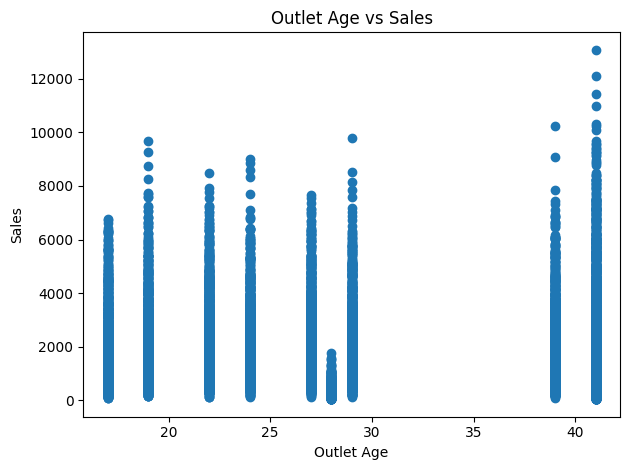

In [37]:
#scatter plot for age and sales
plt.scatter(df["Outlet_Age"], df["Item_Outlet_Sales"])
plt.title("Outlet Age vs Sales")
plt.xlabel("Outlet Age")
plt.ylabel("Sales")
plt.tight_layout()

Text(0, 0.5, 'Total Sales')

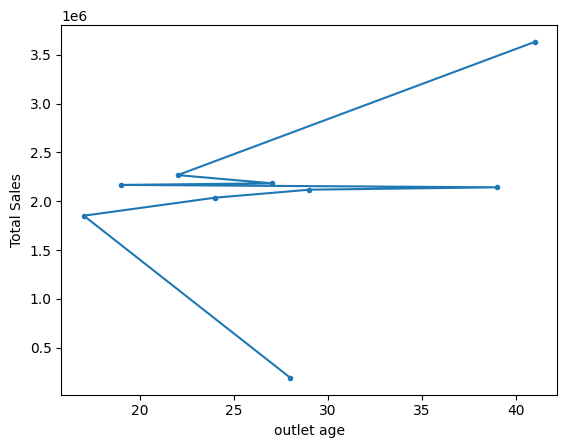

In [38]:
plt.plot(df.groupby("Outlet_Age")["Item_Outlet_Sales"].sum().sort_values(ascending = False),marker = ".")
plt.xlabel("outlet age")
plt.ylabel("Total Sales")

In [39]:
print(df[["Item_MRP", "Item_Outlet_Sales"]].dtypes)

Item_MRP             float64
Item_Outlet_Sales    float64
dtype: object


In [40]:
#we can aslo assume older as the values which are greater than the median
df[df["Outlet_Age"] >= 15].groupby("Item_Type")["Item_Outlet_Sales"].sum().sort_values(ascending=False).idxmax()

'Fruits and Vegetables'

<BarContainer object of 3 artists>

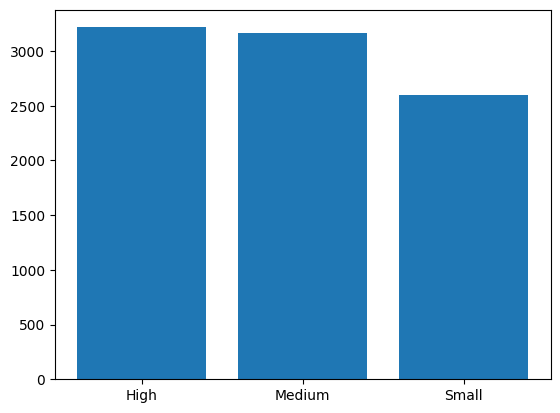

In [41]:
#21
#do expensive products sell better on large outlets
exp = df[(df["Item_MRP"])>=(df["Item_MRP"].median())]
exp   #it has made a new dataframe of only tjose items whise mrp is greater than the average mrp
#since now only we have the df of only expensive products, we have only 2 variables to deal with
t = exp.groupby("Outlet_Size")["Item_Outlet_Sales"].mean().sort_values(ascending = False)
plt.bar(t.index,t.values)
#conclusion - It is not true that the higher priced goods sell more in larger outlets. 
#expensive products generate higher average sales in median stotes than the larger store.
#this means that the size of the store does not determine the sales of expensive products.

In [42]:
#Which outlet type performs best in each city tier?
#outlet type - supermarket, outlet location type - tier 1..., item outlet sales
#when we are grouping by 2 columns, and we want the best performing, we need to further use groupby again to get the highest and the best performing type \
s = df.groupby(["Outlet_Location_Type","Outlet_Type"])["Item_Outlet_Sales"].sum().reset_index()
s.loc[s.groupby("Outlet_Location_Type")["Item_Outlet_Sales"].idxmax()]
#conclusion - different tier city have different outlet types which works for them the best.
#supermarket type 1 works the best in tier 1 and 2 and tier 3 supports supermarket type 3
#the cities should make more only that kind of supermarkets which are best supported in their city.

,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
1,Tier 1,Supermarket Type1,4.302365e+06
2,Tier 2,Supermarket Type1,6.472314e+06
6,Tier 3,Supermarket Type3,3.453926e+06



# Final Conclusion

### Key Insights
- Fruits and Vegetables contribute the highest revenue.
- Low-fat products outperform regular products.
- Tier-wise outlet performance varies significantly.
- MRP has a stronger impact on sales than outlet age.
- Product visibility has little influence on sales.
